In [1]:
import httpx
import pandas as pd

BASE = "https://estadisticas.bcrp.gob.pe/estadisticas/series/api"

def serie_bcrp(codigo, desde="2010-1", hasta="2026-4"):
    url = f"{BASE}/{codigo}/json/{desde}/{hasta}"
    r = httpx.get(url, timeout=30)
    r.raise_for_status()
    datos = r.json()
    nombre = datos["config"]["series"][0]["name"]
    filas = [(p["name"], p["values"][0]) for p in datos["periods"]]
    df = pd.DataFrame(filas, columns=["trimestre", "valor"])
    df["valor"] = pd.to_numeric(df["valor"], errors="coerce")
    return nombre, df

nombre, venta = serie_bcrp("PD17460PQ")
print(nombre)
venta.head()

Venta de departamentos por distrito (dólares corrientes por m2) - Miraflores


,trimestre,valor
0,T1.10,1105.263158
1,T2.10,1228.636364
2,T3.10,1231.800349
3,T4.10,1310.629515
4,T1.11,1315.789474


In [3]:
_, per = serie_bcrp("PD41945PQ")

mira = venta.merge(per, on="trimestre", suffixes=("_venta", "_per"))
mira["alquiler_anual_m2"] = mira["valor_venta"] / mira["valor_per"]
mira["alquiler_mensual_m2"] = mira["alquiler_anual_m2"] / 12
mira.tail()

,trimestre,valor_venta,valor_per,alquiler_anual_m2,alquiler_mensual_m2
46,T1.25,2230.327144,17.581408,126.857143,10.571429
47,T2.25,2211.764706,16.895425,130.909091,10.909091
48,T3.25,2249.969132,16.193189,138.945404,11.578784
49,T4.25,2400.000000,17.500000,137.142857,11.428571
50,T1.26,2463.917526,17.778518,138.589588,11.549132


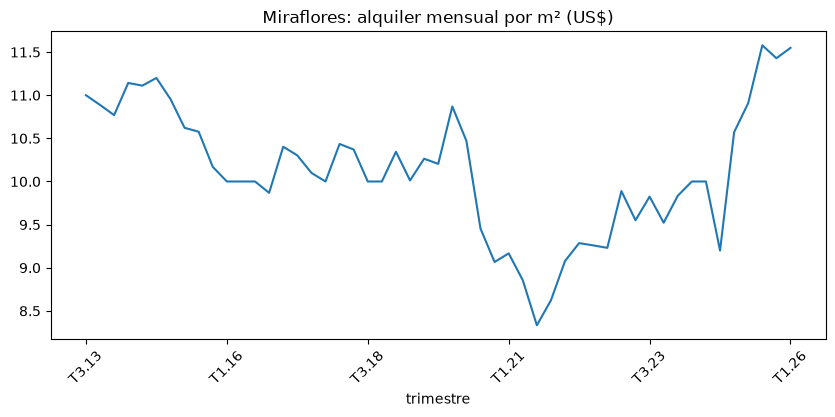

In [4]:
mira.plot(x="trimestre", y="alquiler_mensual_m2", figsize=(10, 4),
          title="Miraflores: alquiler mensual por m² (US$)", legend=False, rot=45);